# Case study: OPS CRISPR screen (TGFBR2 × TNFα)

Optical pooled CRISPR screen with a Cellecta guide library: TGFBR2 knockout, then a short TNFα protein IF readout.

This case study examines one public SpatialData object (SDO): contents, assays and panels,
plate layout, per-cell tables, and an experiment-specific analysis.

**Prerequisites.** Install the package and JupyterLab ([installation guide](../../docs/installation.md)).
[`GettingStarted.ipynb`](../GettingStarted.ipynb) covers loading an SDO and reading its tables.

**Data.** **Cytos-MPS_TNFa-CRISPR-Screen** (~111 GB). Streams from public S3 by default; an optional local download
is described in section 0. No AWS credentials are required.


## 0. Access the data

Dataset: **Cytos-MPS_TNFa-CRISPR-Screen** (~111 GB).

### Default: stream from public S3

The next cell opens the public `spatialdata/` prefix with `storage_options={"anon": True}`.
`Loader` reads tables and metadata remotely; image pyramids and molecule points stay on S3.

### Optional: local download

Download the archive when you need image pyramids, segmentation masks, or other pixel-level work.
Run the commands below from the **`tutorials/`** directory so the file is written to
`tutorials/data/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip`, then uncomment the local-override lines in the next cell
(`SDO_PATH = "../data/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip"` and `STORAGE_OPTIONS = {}`).

**Option A: `curl`**

```bash
mkdir -p data
curl -C - -L -o data/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip \
  "https://element-public-data.s3.us-west-2.amazonaws.com/Cytos/elembio-multiomics/Cytos-MPS_TNFa-CRISPR-Screen/0c47c400756647deb9b3a37f502458de/spatialdata/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip"
```

If the download stops, run the same command again to resume. On Windows PowerShell, use `curl.exe`.

**Option B: AWS CLI**

```bash
mkdir -p data
aws s3 cp \
  s3://element-public-data/Cytos/elembio-multiomics/Cytos-MPS_TNFa-CRISPR-Screen/0c47c400756647deb9b3a37f502458de/spatialdata/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip \
  data/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip \
  --no-sign-request
```

Do not unzip the archive; `Loader` reads `.zarr.zip` directly.


In [1]:
%matplotlib inline
import warnings

import fsspec
import numpy as np
import pandas as pd
import s3fs
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import Markdown, display

from elembio_spatialdata_analysis.load import Loader

# Quiet known library noise (matmul / overflow RuntimeWarnings from DESeq2 fits).
warnings.filterwarnings("ignore", message="Did not read zarr as consolidated")
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"sklearn\..*")
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"pydeseq2\..*")
warnings.filterwarnings(
    "ignore",
    message=r".*encountered in matmul",
    category=RuntimeWarning,
)

# ---- default: stream from the public spatialdata/ prefix ----
SPATIALDATA_PREFIX = (
    "s3://element-public-data/Cytos/elembio-multiomics/Cytos-MPS_TNFa-CRISPR-Screen/0c47c400756647deb9b3a37f502458de/spatialdata"
)
STORAGE_OPTIONS = {"anon": True}

# Optional local override (after downloading into tutorials/data/):
# SDO_PATH = "../data/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip"
# STORAGE_OPTIONS = {}

fs = s3fs.S3FileSystem(**STORAGE_OPTIONS)
prefix_key = SPATIALDATA_PREFIX.removeprefix("s3://").rstrip("/")


def human_size(n: int) -> str:
    if n >= 1e9:
        return f"{n / 1e9:.2f} GB"
    if n >= 1e6:
        return f"{n / 1e6:.1f} MB"
    return f"{n / 1e3:.1f} kB"


def list_objects(key: str) -> pd.DataFrame:
    """Real objects directly under an S3 prefix, dropping directory markers."""
    columns = ["name", "size", "size_bytes", "uri"]
    try:
        entries = fs.ls(key, detail=True)
    except FileNotFoundError:
        return pd.DataFrame(columns=columns)
    rows = [
        {
            "name": entry["name"].rsplit("/", 1)[-1],
            "size": human_size(entry["size"]),
            "size_bytes": entry["size"],
            "uri": "s3://" + entry["name"],
        }
        for entry in entries
        if entry["type"] == "file" and entry["name"].rsplit("/", 1)[-1]
    ]
    return pd.DataFrame(rows, columns=columns).sort_values("size_bytes", ascending=False).reset_index(drop=True)


if "SDO_PATH" not in globals():
    prefix_objects = list_objects(prefix_key)
    sdo_candidates = prefix_objects.loc[prefix_objects["name"].str.endswith(".zarr.zip")]
    if len(sdo_candidates) != 1:
        raise RuntimeError(
            f"Expected exactly one *.zarr.zip under {SPATIALDATA_PREFIX}, found {len(sdo_candidates)}."
        )
    SDO_PATH = sdo_candidates["uri"].iloc[0]
    display(Markdown("### Objects in the public prefix"))
    display(prefix_objects[["name", "size"]])
    print("SDO:    ", SDO_PATH)
    print("access: anonymous (public bucket)")

loader = Loader(SDO_PATH, storage_options=STORAGE_OPTIONS)
run = next(iter(loader._runs.values()))
print(loader.summary())


### Objects in the public prefix

,name,size
0,Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip,111.21 GB
1,points-zarr.zip,6.49 GB
2,cell-shapes-zarr.zip,87.8 MB
3,nuclear-shapes-zarr.zip,31.3 MB
4,cyto.viz,14.3 MB
5,Cytos-MPS_TNFa-CRISPR-Screen.zarr-index.bin,560.1 kB
6,Cytos-MPS_TNFa-CRISPR-Screen.points-zarr-index...,0.3 kB
7,Cytos-MPS_TNFa-CRISPR-Screen.nuclear-shapes-za...,0.1 kB
8,Cytos-MPS_TNFa-CRISPR-Screen.cell-shapes-zarr-...,0.1 kB


SDO:     s3://element-public-data/Cytos/elembio-multiomics/Cytos-MPS_TNFa-CRISPR-Screen/0c47c400756647deb9b3a37f502458de/spatialdata/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip
access: anonymous (public bucket)


--- Cytos-MPS_TNFa-CRISPR-Screen ---
  run_name:       Cytos-MPS_TNFa-CRISPR-Screen
  source:         s3://element-public-data/Cytos/elembio-multiomics/Cytos-MPS_TNFa-CRISPR-Screen/0c47c400756647deb9b3a37f502458de/spatialdata/Cytos-MPS_TNFa-CRISPR-Screen.zarr.zip
  tables:         ['B01-Cellecta', 'B01-QC_Panel', 'ThreePrimeUntargeted', 'imaging']
  batches (8):   B01 (SpecializedTargeted), B02 (ThreePrimeUntargeted), B03 (ThreePrimeUntargeted), B04 (ThreePrimeUntargeted), B05 (ThreePrimeUntargeted), B06 (ThreePrimeUntargeted), CP01 (PreAmp), P01 (PreAmp)
  wells (12):     A1, A2, B1, B2, C1, C2, D1, D2, ... (12 total)
  tiles:          144
  points:         72 elements (well mode)
  build:          1.0.0rc15


## 1. What is inside the SDO

The archive is a SpatialData Zarr store with five kinds of element:

| Element | Contents | Opened with |
|---|---|---|
| Tables | Per-cell AnnData, one per assay | `Loader.load_tables` |
| Points | Per-molecule / polony locations | `Loader.load_points` |
| Images | Multiscale pixel pyramids | `spatialdata.read_zarr` (directory store) |
| Labels | Segmentation masks | `spatialdata.read_zarr` |
| Shapes | Vector segmentation boundaries | `spatialdata.read_zarr` |

How the tables are organized:

- **Imaging is one table holding two assays.** Morphology (CellPaint) stains and protein
  immunofluorescence markers are measured on the same cells and stored together in the
  `imaging` table, separated by `target_type`.
- **Table names come from the run.** An OPS / identity panel name includes a run-specific
  suffix. Imaging appears as `imaging` (or the legacy alias `CellPaint`).

`Loader` reads the archive index and tables remotely. Image and segmentation work
requires a local directory store or mount and is covered separately.


In [2]:
# Which target_type each loadable table belongs to.
types_by_table: dict[str, set[str]] = {}
for target_type in sorted(loader.available_target_types):
    for suffix in run.table_suffixes_for_target_type((target_type,)):
        types_by_table.setdefault(suffix, set()).add(target_type)

CONTENTS_BY_TYPE = {
    "OPS": "identity or control panel",
    "SpecializedTargeted": "identity or control panel",
    "ThreePrimeUntargeted": "3′ RNA counts",
    "imaging": "morphology + protein IF",
}

tables = pd.DataFrame(
    [
        {
            "table": name,
            "target_type": ", ".join(sorted(types_by_table.get(name, {"(unlabelled)"}))),
            "contents": " / ".join(
                dict.fromkeys(
                    CONTENTS_BY_TYPE.get(t, "see metadata")
                    for t in sorted(types_by_table.get(name, []))
                )
            )
            or "see metadata",
        }
        for name in sorted(loader.available_tables)
    ]
)
display(Markdown("### Analysis tables in this SDO"))
display(tables)


def spatial_element_inventory(sdo_uri: str, storage_options: dict) -> pd.DataFrame:
    """Count SpatialData elements from the archive index — no pixel data is fetched."""
    if str(sdo_uri).startswith("s3://"):
        archive = fsspec.filesystem(
            "zip", fo=sdo_uri, target_protocol="s3", target_options=storage_options
        )
    else:
        archive = fsspec.filesystem("zip", fo=sdo_uri)
    roots = [
        str(e).rstrip("/")
        for e in archive.ls("/", detail=False)
        if str(e).rstrip("/").endswith(".zarr")
    ]
    if len(roots) != 1:
        raise RuntimeError(f"Expected one *.zarr root inside the archive, found {roots}.")
    root = roots[0]

    rows = []
    for element in ("tables", "images", "labels", "shapes", "points"):
        try:
            entries = archive.ls(f"{root}/{element}", detail=False)
        except FileNotFoundError:
            entries = []
        names = sorted(
            n
            for n in (str(x).rsplit("/", 1)[-1] for x in entries)
            if n and not n.endswith(".json")
        )
        rows.append({"element": element, "count": len(names), "examples": ", ".join(names[:2])})
    return pd.DataFrame(rows)


elements = spatial_element_inventory(SDO_PATH, STORAGE_OPTIONS)
display(Markdown("### All elements stored in the archive"))
display(elements)

n_archive_tables = int(elements.loc[elements["element"].eq("tables"), "count"].iloc[0])
print(
    f"{n_archive_tables} table groups in the archive vs {len(loader.available_tables)} loadable assay tables — "
    "the extra one is global-table-metadata (wells, tiles, batches, targets)."
)


### Analysis tables in this SDO

,table,target_type,contents
0,B01-Cellecta,OPS,identity or control panel
1,B01-QC_Panel,OPS,identity or control panel
2,ThreePrimeUntargeted,ThreePrimeUntargeted,3′ RNA counts
3,imaging,imaging,morphology + protein IF


### All elements stored in the archive

,element,count,examples
0,tables,5,"global-table-B01-Cellecta, global-table-B01-QC..."
1,images,12,"A1-images-cell_paint, A2-images-cell_paint"
2,labels,24,"A1-labels-Cell, A1-labels-Nuclear"
3,shapes,24,"A1-shapes-Cell, A1-shapes-Nuclear"
4,points,72,"A1-points-B01, A1-points-B02"


5 table groups in the archive vs 4 loadable assay tables — the extra one is global-table-metadata (wells, tiles, batches, targets).


## 2. Which assays were run, and what panels

Run metadata splits what the compact table names hide:

- `run.targets_imaging` separates CellPaint morphology stains from Protein IF markers.
- Panel metadata distinguishes cell-assigning identity panels from untargeted 3′ RNA,
  and flags control panels with `IsControl`.

**`control_type` — what it means.** A few channels exist to validate the assay:

| `control_type` | Role |
|---|---|
| `Positive…` | Expected to stain strongly in every cell. Weak signal flags a staining or imaging problem |
| `Negative…` | Antibody isotype controls (IgG); a floor for non-specific binding |
| empty | An ordinary readout — most of the panel |

Isotype and background channels are usually excluded from profiling matrices used for embeddings.


In [3]:
imaging_targets = run.targets_imaging.copy()
diss_targets = run.diss_targets_metadata.copy()


def as_bool(series: pd.Series) -> pd.Series:
    """Metadata booleans arrive as bool, string, or NaN depending on build version."""
    return series.astype(str).str.lower().isin({"true", "1", "yes"})


def control_role(value: object) -> str:
    text = "" if value is None else str(value).strip()
    if text.lower().startswith("positive"):
        return "positive staining control"
    if text.lower().startswith("negative"):
        return "isotype control"
    return "readout"


morphology_panel = imaging_targets.loc[imaging_targets["target_type"].eq("CellPaint")].copy()
protein_panel = imaging_targets.loc[imaging_targets["target_type"].eq("ProteinIF")].copy()
for panel in (morphology_panel, protein_panel):
    panel["role"] = panel["control_type"].map(control_role)

assigns_cells = as_bool(diss_targets["CellAssignment"])
is_control = (
    as_bool(diss_targets["IsControl"])
    if "IsControl" in diss_targets.columns
    else pd.Series(False, index=diss_targets.index)
)
identity_sites = diss_targets.loc[assigns_cells & ~is_control, "TargetSiteName"].tolist()
control_sites = diss_targets.loc[assigns_cells & is_control, "TargetSiteName"].tolist()
untargeted = diss_targets.loc[~assigns_cells]
untargeted_batches = sorted(untargeted["batch_name"].unique()) if "batch_name" in untargeted else []

rows = []
if identity_sites:
    rows.append(("Identity / OPS panel", ", ".join(identity_sites), "assigns each cell to a library member"))
if control_sites:
    rows.append(("Control panel", ", ".join(control_sites), "diagnostic when identity counts come out low"))
if untargeted_batches:
    rows.append((
        "3′ untargeted RNA",
        f"{len(untargeted_batches)} batches ({len(untargeted)} RT target sites)",
        "per-cell transcript counts",
    ))
if len(morphology_panel):
    rows.append(("CellPaint morphology", f"{len(morphology_panel)} stains", "intensity, localisation, CellProfiler features"))
if len(protein_panel):
    n_readout = int(protein_panel["role"].eq("readout").sum())
    n_isotype = int(protein_panel["role"].eq("isotype control").sum())
    rows.append(("Protein IF", f"{n_readout} markers + {n_isotype} isotype controls", "protein abundance and localisation"))

display(Markdown("### Assays present, from run metadata"))
display(pd.DataFrame(rows, columns=["assay", "panel", "readout"]))

panel_columns = ["target_name", "role", "control_type", "batch_name"]
if len(morphology_panel):
    display(Markdown("### CellPaint / morphology panel"))
    display(morphology_panel[panel_columns].reset_index(drop=True))
if len(protein_panel):
    display(Markdown("### Protein IF panel"))
    display(protein_panel[panel_columns].reset_index(drop=True))

print(f"wells: {len(run.wells)}   tiles: {len(run.tiles)}")
print("imaging batches:", sorted(imaging_targets["batch_name"].unique()))

### Assays present, from run metadata

,assay,panel,readout
0,Identity / OPS panel,Cellecta,assigns each cell to a library member
1,Control panel,QC_Panel,diagnostic when identity counts come out low
2,3′ untargeted RNA,5 batches (5 RT target sites),per-cell transcript counts
3,CellPaint morphology,4 stains,"intensity, localisation, CellProfiler features"
4,Protein IF,4 markers + 2 isotype controls,protein abundance and localisation


### CellPaint / morphology panel

,target_name,role,control_type,batch_name
0,Mitochondria,positive staining control,Positive1,CP01
1,Cell-Membrane,readout,,CP01
2,Nucleus,readout,,CP01
3,Actin,readout,,CP01


### Protein IF panel

,target_name,role,control_type,batch_name
0,Mouse_IgG,isotype control,Negative1,P01
1,Rabbit_IgG,isotype control,Negative2,P01
2,Phospho-ERK1_Phospho-ERK2,readout,,P01
3,ERK1_ERK2,readout,,P01
4,Phospho-HSP27,readout,,P01
5,Phospho-p38,readout,,P01


wells: 12   tiles: 144
imaging batches: ['CP01', 'P01']


## 3. Plate layout

Well identity and labels come from run metadata (`run.wells`).

Two fields to know:

- **`cell_type`** is the segmentation model used to find cells (chosen for nuclear and cell size).
  That name often differs from the biological sample.
- **`well_label`** is free text set at run configuration. The schematic colours wells by the
  stored label. Mapping those strings to treatment, dose, timepoint, or replicate is part of
  interpreting the experiment.


### Wells as stored in run metadata

,well_name,well_label,cell_type,well_layout,target_site_names
0,A1,Cellecta,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
1,A2,CellectaTNFa,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
2,B1,Cellecta,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
3,B2,CellectaTNFa,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
4,C1,Cellecta,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
5,C2,CellectaTNFa,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
6,D1,CellectaTNFa,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
7,D2,Cellecta,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
8,E1,CellectaTNFa,HELA,TwelveWellStandard,"QC_Panel, Cellecta"
9,E2,Cellecta,HELA,TwelveWellStandard,"QC_Panel, Cellecta"


cell_type holds segmentation model(s): ['HELA']
distinct well_label values: ['Cellecta', 'CellectaTNFa']


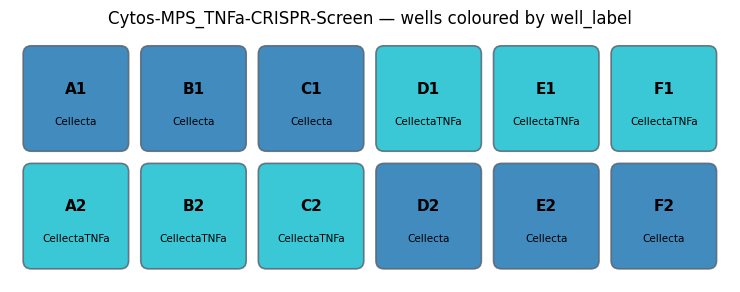

In [4]:
wells = run.wells.copy()
if wells.empty:
    raise RuntimeError("Run metadata carries no wells table — this store has no global-table-metadata.")
if "well_name" not in wells.columns:
    wells = wells.reset_index().rename(columns={wells.index.name or "index": "well_name"})
wells["well_name"] = wells["well_name"].astype(str)

shown = [c for c in ("well_name", "well_label", "cell_type", "well_layout", "target_site_names") if c in wells.columns]
display(Markdown("### Wells as stored in run metadata"))
display(wells[shown].sort_values("well_name").reset_index(drop=True))
if "cell_type" in wells.columns:
    print("cell_type holds segmentation model(s):", sorted(wells["cell_type"].astype(str).unique()))
print("distinct well_label values:", sorted(wells["well_label"].astype(str).unique()))

# Grid derived from the well names themselves, e.g. "C2" -> column C, row 2.
parsed = wells["well_name"].str.extract(r"^(?P<col>[A-Za-z]+)(?P<row>\d+)$")
if parsed.isna().any().any():
    raise RuntimeError("Unexpected well naming; cannot derive a plate grid.")
wells = pd.concat([wells, parsed], axis=1)
columns = sorted(wells["col"].unique())
rows = sorted(wells["row"].unique(), key=int)

labels = sorted(wells["well_label"].astype(str).unique())
palette = plt.get_cmap("tab10", max(len(labels), 1))
label_colors = {label: palette(i) for i, label in enumerate(labels)}

fig, ax = plt.subplots(figsize=(1.55 * len(columns), 1.8 * len(rows)))
side, gap = 1.0, 0.16
for ci, col in enumerate(columns):
    for ri, row in enumerate(rows):
        record = wells.loc[(wells["col"] == col) & (wells["row"] == row)]
        if record.empty:
            continue
        label = str(record["well_label"].iloc[0])
        x, y = ci * (side + gap), (len(rows) - 1 - ri) * (side + gap)
        ax.add_patch(
            FancyBboxPatch(
                (x, y), side, side,
                boxstyle="round,pad=0.02,rounding_size=0.08",
                facecolor=label_colors[label], edgecolor="#5A6570", linewidth=1.2, alpha=0.85,
            )
        )
        ax.text(x + side / 2, y + side * 0.6, f"{col}{row}", ha="center", va="center", fontsize=11, fontweight="bold")
        ax.text(x + side / 2, y + side * 0.28, label, ha="center", va="center", fontsize=7.5)
ax.set_xlim(-0.15, len(columns) * (side + gap))
ax.set_ylim(-0.15, len(rows) * (side + gap))
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"{run.run_name} — wells coloured by well_label")
plt.show()

## 4. Load the per-cell tables

Tables can be loaded lazily so matrices stay on disk until analysis needs them. All tables
share the same cells (`n_obs` matches), but **a "feature" means something different in each table**:

| Table | One feature is |
|---|---|
| Identity / OPS | one guide (or barcode) in the library |
| Control panel | one control probe |
| 3′ untargeted | one gene model from the GENCODE annotation |
| Imaging | one measurement per cell (channel intensity, localisation ratio, or CellProfiler feature) |

Pass the identity table name returned by `table_suffixes_for_target_type`. A `target_type` of
`OPS` covers both identity libraries and control panels; assignment gating applies to the
identity library.


In [5]:
specialized = list(run.table_suffixes_for_target_type(("OPS", "SpecializedTargeted")))
control_site_names = {name.lower() for name in control_sites}
identity_tables = [t for t in specialized if t.split("-", 1)[-1].lower() not in control_site_names]
control_tables = [t for t in specialized if t not in identity_tables]
imaging_alias = sorted({"imaging", "CellPaint"} & set(loader.available_tables))
has_three_prime = "ThreePrimeUntargeted" in loader.available_tables

identity = loader.load_tables(table=identity_tables[0], lazy=True, include_target_assignment=True) if identity_tables else None
control = loader.load_tables(table=control_tables[0], lazy=True) if control_tables else None
imaging = loader.load_tables(table="imaging", lazy=True) if imaging_alias else None
rna = loader.load_tables(table="ThreePrimeUntargeted", lazy=True) if has_three_prime else None

loaded = {}
if identity is not None:
    loaded[identity_tables[0]] = (identity, "a guide in the library")
if control is not None:
    loaded[control_tables[0]] = (control, "a control probe")
if imaging is not None:
    loaded["imaging"] = (imaging, "an imaging measurement")
if rna is not None:
    loaded["ThreePrimeUntargeted"] = (rna, "a GENCODE gene model")

display(Markdown("### Loaded tables"))
display(pd.DataFrame(
    [
        {"table": name, "cells": f"{table.n_obs:,}", "features": f"{table.n_vars:,}", "a feature is": meaning}
        for name, (table, meaning) in loaded.items()
    ]
))

### Loaded tables

,table,cells,features,a feature is
0,B01-Cellecta,"258,896",28,a guide in the library
1,B01-QC_Panel,"258,896",8,a control probe
2,imaging,"258,896","1,150",an imaging measurement
3,ThreePrimeUntargeted,"258,896","54,949",a GENCODE gene model


## 5. What those features are

The same counts, broken down from each table's `var` metadata — so a large feature count becomes
something you can inspect directly.


In [6]:
def var_frame(table) -> pd.DataFrame:
    """`var` as pandas, whether the table was read lazily (Dataset2D) or eagerly (DataFrame)."""
    var = table.var
    if isinstance(var, pd.DataFrame):
        return var
    names = list(var.columns) if hasattr(var, "columns") else list(var.keys())
    return pd.DataFrame(
        {name: np.asarray(var[name]) for name in names},
        index=pd.Index(np.asarray(table.var_names), name="feature"),
    )


if identity is not None:
    library = (
        pd.Series(np.asarray(identity.var_names)).astype(str)
        .str.replace(r"_\d+$", "", regex=True)
        .value_counts().rename_axis("library_member").reset_index(name="n_guides")
    )
    display(Markdown(f"**Identity library** — {identity.n_vars} guides across {len(library)} members"))
    display(library)

if control is not None:
    control_var = var_frame(control)
    gene_column = "target_gene" if "target_gene" in control_var.columns else None
    display(Markdown(f"**Control panel** — {control.n_vars} probes"))
    display(control_var[[c for c in ("target_gene", "control_type", "batch_name") if c in control_var.columns]])

if rna is not None:
    rna_var = var_frame(rna)
    display(Markdown(f"**3′ untargeted** — {rna.n_vars:,} gene models, by annotation class"))
    if "gene_type" in rna_var.columns:
        breakdown = rna_var["gene_type"].value_counts().rename_axis("gene_type").reset_index(name="n_genes")
        display(breakdown.head(10))
        print("protein-coding genes:", int(rna_var["gene_type"].eq("protein_coding").sum()))
    if "feature" in rna_var.columns:
        print("GTF feature level:", pd.Series(rna_var["feature"]).value_counts().to_dict())

if imaging is not None:
    imaging_var = var_frame(imaging)
    display(Markdown(f"**Imaging** — {imaging.n_vars:,} measurements per cell"))
    summary = []
    GROUP_LABELS = {"base": "intensity / localisation", "cellprofiler": "CellProfiler"}
    if "feature_class" in imaging_var.columns:
        for feature_class, n in imaging_var["feature_class"].value_counts().items():
            summary.append({
                "group": GROUP_LABELS.get(feature_class, str(feature_class)),
                "n_features": int(n),
            })
    if "is_background" in imaging_var.columns:
        n_background = int(imaging_var["is_background"].astype(str).str.lower().isin({"true", "1"}).sum())
        summary.append({"group": "background (subset, excluded)", "n_features": n_background})
    display(pd.DataFrame(summary))
    geometry = imaging.obsm.get("cell_geometry")
    if geometry is not None:
        print(f"plus {geometry.shape[1]} per-cell geometry columns in obsm['cell_geometry'] (Area, AreaShape_*, …)")

**Identity library** — 28 guides across 7 members

,library_member,n_guides
0,NT_Human_CRko_BB,4
1,CTNNB1,4
2,GSK3B,4
3,IL1R1,4
4,OR1I1,4
5,SMAD7,4
6,TGFBR2,4


**Control panel** — 8 probes

,target_gene,control_type,batch_name
GAPDH_1248-1823,GAPDH,,B01
GAPDH_542-564,GAPDH,,B01
GAPDH_146-180,GAPDH,,B01
GAPDH_987-1025,GAPDH,,B01
ACTB_1402-1438,ACTB,,B01
ACTB_1755-1785,ACTB,,B01
ACTB_1087-1110,ACTB,,B01
ACTB_811-834,ACTB,,B01


**3′ untargeted** — 54,949 gene models, by annotation class

,gene_type,n_genes
0,lncRNA,34853
1,protein_coding,20063
2,transcribed_unprocessed_pseudogene,20
3,transcribed_processed_pseudogene,6
4,transcribed_unitary_pseudogene,5
5,processed_pseudogene,1
6,None,1


protein-coding genes: 20063
GTF feature level: {'gene': 54948, 'None': 1}


**Imaging** — 1,150 measurements per cell

,group,n_features
0,CellProfiler,910
1,intensity / localisation,240
2,"background (subset, excluded)",140


plus 23 per-cell geometry columns in obsm['cell_geometry'] (Area, AreaShape_*, …)


## 6. Experiment-specific analysis

This experiment pools CRISPR guides within every well, so each untreated well contains both TGFBR2-targeting
and non-targeting cells. The untreated arm has six such wells. We compare TGFBR2 versus non-targeting cells
*within each untreated well*, then use the well as the replicate unit. Cells that share a well count as one sample.

Guide calls use `Confidence > 0.5`, the high-confidence cutoff used for this tutorial summary. On this run that
assigns about 87% of cells, matching the dataset description.

The three subsections are separate on purpose, and each one runs on its own once the cell below has run:

1. 3′ RNA pseudobulk volcano — TGFBR2-KO versus non-targeting, untreated wells
2. CellPaint morphology contrast — the same comparison, read from the images
3. Protein IF UMAP — TNFα-treated versus untreated single-cell signaling state

The analysis below also uses `pydeseq2`, `statsmodels`, and `umap-learn`, which install with this package.


In [7]:
# Shared setup for 6.1-6.3: guide calls, condition labels, and plot helpers.
ASSIGNMENT_THRESHOLD = 0.5
TARGET_GENE = "TGFBR2"
UP_COLOR, DOWN_COLOR, BACKGROUND_COLOR = "#E8793E", "#6C4CCF", "#C8CBD4"


def string_values(values) -> np.ndarray:
    """Plain object strings from pandas, xarray, or an AnnData index."""
    return pd.Series(np.asarray(values)).astype(str).to_numpy(dtype=object)


# All modalities should describe the same cells in the same order.
for table_name, table in (("RNA", rna), ("imaging", imaging)):
    if table is not None and not np.array_equal(np.asarray(identity.obs_names), np.asarray(table.obs_names)):
        raise RuntimeError(f"Identity and {table_name} tables are not aligned by cell.")

assignment = identity.obsm["target_assignment"]
winner = string_values(assignment["MostAbundantTarget"])
confidence = np.asarray(assignment["Confidence"], dtype=float)
guide_names = string_values(identity.var_names)

# Collapse the four guides per target to a gene-level identity.
guide_gene = np.array(
    ["NT" if name.startswith("NT_") else name.rsplit("_", 1)[0] for name in winner],
    dtype=object,
)
valid_assignment = np.isin(winner, guide_names) & (confidence > ASSIGNMENT_THRESHOLD)

cell_well = string_values(identity.obs["Well"])
well_label = string_values(identity.obs["WellLabel"])
condition = np.where(
    pd.Series(well_label).str.contains("TNFa", case=False).to_numpy(),
    "TNFα",
    "untreated",
)

# The knockout comparison used by 6.1 and 6.2: TGFBR2 vs non-targeting, untreated wells only.
untreated = condition == "untreated"
analysis_cells = valid_assignment & untreated & np.isin(guide_gene, [TARGET_GENE, "NT"])

# Column lookup for the imaging table, used by 6.2 and 6.3.
imaging_position = {name: i for i, name in enumerate(string_values(imaging.var_names))}


def label_points(ax, points, outward=True, gap=0.04, pad=7, fontsize=9):
    """Write labels beside points, without leader lines.

    `points` needs x, y, label and color columns. A label sits away from the
    y-axis (`outward`) or toward it, except that two points at the same height
    send their labels to opposite sides so neither is written across the other's
    marker. A label that would still collide moves to the other side of its own
    point, and only drops down the axis when both sides are blocked. Call this
    after `fig.tight_layout()` — label widths are estimated from the final axes.
    """
    ax.figure.canvas.draw()
    (bottom, top), (left, right) = ax.get_ylim(), ax.get_xlim()
    per_point = (right - left) / (ax.get_window_extent().width * 72 / ax.figure.dpi)
    min_gap = (top - bottom) * gap
    written = []

    def blocked(x, y, side, width):
        """y positions of labels this one would run into."""
        near, far = sorted((x, x + side * width))
        return [other_y for start, end, other_y in written
                if abs(y - other_y) < min_gap and near < end and start < far]

    for _, point in points.sort_values("y", ascending=False).iterrows():
        width = (pad + 0.55 * fontsize * len(point["label"])) * per_point
        level = points[(abs(points["y"] - point["y"]) < min_gap)
                       & (abs(points["x"] - point["x"]) < 2 * width)
                       & (points["x"] != point["x"])]
        if len(level):
            preferred = 1 if point["x"] >= level["x"].max() else -1
        else:
            preferred = int(np.sign(point["x"]) * (1 if outward else -1))
        side = next((option for option in (preferred, -preferred)
                     if not blocked(point["x"], point["y"], option, width)), preferred)
        collisions = blocked(point["x"], point["y"], side, width)
        y_text = min(collisions) - min_gap if collisions else point["y"]
        written.append((*sorted((point["x"], point["x"] + side * width)), y_text))
        ax.annotate(
            point["label"], (point["x"], y_text),
            xytext=(pad * side, 0), textcoords="offset points",
            ha="left" if side > 0 else "right", va="center",
            fontsize=fontsize, color=point["color"],
        )


print(f"Assigned at Confidence > {ASSIGNMENT_THRESHOLD}: {valid_assignment.mean():.1%}")
print(f"{TARGET_GENE} vs non-targeting, untreated wells: {analysis_cells.sum():,} cells")
display(pd.crosstab(
    pd.Series(guide_gene[valid_assignment], name="guide target"),
    pd.Series(condition[valid_assignment], name="condition"),
))

Assigned at Confidence > 0.5: 87.2%
TGFBR2 vs non-targeting, untreated wells: 18,716 cells


condition,TNFα,untreated
guide target,,
CTNNB1,24375,25355
GSK3B,18753,18220
IL1R1,7220,7784
NT,14582,14868
OR1I1,37466,38143
SMAD7,5590,5652
TGFBR2,3781,3848


### 6.1 RNA response to TGFBR2 knockout

Raw 3′ counts are summed separately for TGFBR2 and non-targeting cells in each untreated well. DESeq2 then
compares the six TGFBR2 pseudobulks with the six non-targeting pseudobulks. This preserves the correct replicate
unit while using all assigned cells.

Positive log2FC means increased in TGFBR2-KO; negative means reduced. Labels mark a small curated set for this
story: the receptor itself, four canonical TGF-β/EMT targets
that fall with it, and CCN5 (WISP2), which TGF-β normally represses and which therefore rises when the receptor
is lost. The table underneath reports the same genes.

Two things are worth reading carefully. The receptor transcript itself goes down, which confirms on-target
editing. PMEPA1, TGFBI, CDH2, and IGFBP7 go down with it — the expected consequence of disrupting the axis.
CCN5 going up is the expected rise once TGF-β repression is relieved.


guide_class,NT,TGFBR2
Well,,
A1,2399,620
B1,2557,644
C1,2465,668
D2,2538,668
E2,2365,614
F2,2544,634


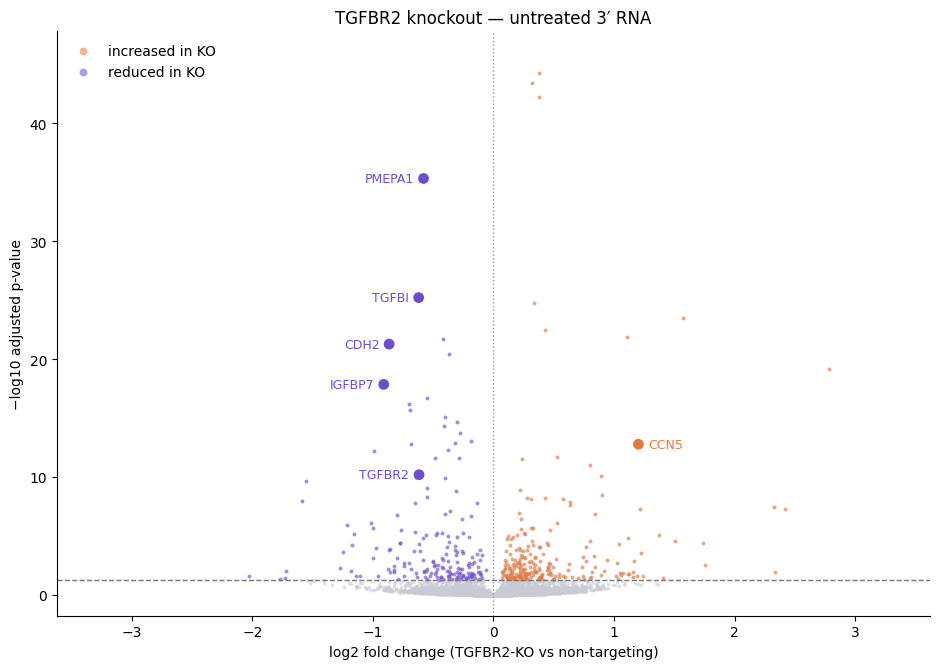

Labeled genes:


,baseMean,log2FoldChange,padj
IGFBP7,157.537572,-0.910099,1.418798e-18
CDH2,198.790684,-0.865181,5.457266e-22
TGFBI,833.437016,-0.620301,6.209539e-26
TGFBR2,195.046761,-0.616987,6.520157e-11
PMEPA1,1589.517140,-0.579888,4.910810e-36
CCN5,55.244363,1.201875,1.699837e-13


Genes tested: 12,648; padj < 0.05: 400


In [8]:
from dask import delayed
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

pd.set_option("future.infer_string", False)  # required by the current PyDESeq2/pandas combination

untreated_wells = sorted(np.unique(cell_well[analysis_cells]))
groups = [(well, cls) for well in untreated_wells for cls in (TARGET_GENE, "NT")]

group_code = np.full(identity.n_obs, -1, dtype=np.int16)
for number, (well, cls) in enumerate(groups):
    group_code[analysis_cells & (cell_well == well) & (guide_gene == cls)] = number

cell_counts = pd.DataFrame(
    [{"Well": well, "guide_class": cls, "cells": int((group_code == i).sum())}
     for i, (well, cls) in enumerate(groups)]
)
if (cell_counts["cells"] < 20).any():
    raise RuntimeError("At least one pseudobulk has fewer than 20 cells.")
display(cell_counts.pivot(index="Well", columns="guide_class", values="cells"))


def aggregate_sparse_block(block, codes, n_groups, n_features):
    """Aggregate one sparse row chunk without materialising the full cell × gene matrix."""
    out = np.zeros((n_groups, n_features), dtype=np.int64)
    for group in np.unique(codes):
        if group >= 0:
            out[group] = np.asarray(block[codes == group].sum(axis=0)).ravel()
    return out


def add_blocks(left, right):
    return left + right


# Loader's lazy RNA matrix is chunked sparse data. Aggregate each row chunk, then tree-reduce.
partials = []
start = 0
for block, n_rows in zip(rna.X.to_delayed().ravel(), rna.X.chunks[0]):
    partials.append(delayed(aggregate_sparse_block)(
        block, group_code[start:start + n_rows], len(groups), rna.n_vars
    ))
    start += n_rows
while len(partials) > 1:
    partials = [
        delayed(add_blocks)(partials[i], partials[i + 1]) if i + 1 < len(partials) else partials[i]
        for i in range(0, len(partials), 2)
    ]

pseudobulk_matrix = partials[0].compute()
sample_names = [f"{well}_{cls}" for well, cls in groups]
rna_counts = pd.DataFrame(pseudobulk_matrix, index=sample_names, columns=string_values(rna.var_names))
rna_counts = rna_counts.loc[:, rna_counts.sum(axis=0) >= len(rna_counts) * 5]

rna_design = pd.DataFrame(
    {"guide_class": ["target" if cls == TARGET_GENE else "NT" for _, cls in groups]},
    index=sample_names,
)
dds = DeseqDataSet(counts=rna_counts, metadata=rna_design, design="~guide_class", quiet=True)
dds.deseq2()
stats = DeseqStats(dds, contrast=["guide_class", "target", "NT"], quiet=True)
stats.summary()
rna_de = stats.results_df.sort_values("padj")

plot_df = rna_de.dropna(subset=["padj", "log2FoldChange"]).copy()
plot_df["minus_log10_padj"] = -np.log10(plot_df["padj"].clip(lower=1e-300))

# Curated labels for the tutorial story — on-target KO, four TGF-β/EMT targets,
# and CCN5 (normally TGF-β-repressed, so expected to rise). Not a top-hit list.
STORY_LABELS = ["TGFBR2", "PMEPA1", "TGFBI", "CDH2", "IGFBP7", "CCN5"]
labelled = plot_df.loc[plot_df.index.intersection(STORY_LABELS)]
missing = [g for g in STORY_LABELS if g not in labelled.index]
if missing:
    raise RuntimeError(f"Story genes missing from DE results: {missing}")

fig, ax = plt.subplots(figsize=(9.5, 6.8))
ax.scatter(plot_df["log2FoldChange"], plot_df["minus_log10_padj"],
           s=7, c=BACKGROUND_COLOR, alpha=0.55, linewidths=0)
significant = plot_df["padj"] < 0.05
for rising, color, legend in ((True, UP_COLOR, "increased in KO"), (False, DOWN_COLOR, "reduced in KO")):
    side = significant & ((plot_df["log2FoldChange"] > 0) == rising)
    ax.scatter(plot_df.loc[side, "log2FoldChange"], plot_df.loc[side, "minus_log10_padj"],
               s=8, c=color, alpha=0.55, linewidths=0, label=legend)
ax.scatter(labelled["log2FoldChange"], labelled["minus_log10_padj"],
           s=60, c=np.where(labelled["log2FoldChange"] > 0, UP_COLOR, DOWN_COLOR),
           linewidths=0, zorder=4)

ax.axhline(-np.log10(0.05), color="#777", ls="--", lw=1)
ax.axvline(0, color="#999", ls=":", lw=1)
ax.set(xlabel="log2 fold change (TGFBR2-KO vs non-targeting)",
       ylabel="−log10 adjusted p-value",
       title="TGFBR2 knockout — untreated 3′ RNA")
widest = plot_df["log2FoldChange"].abs().max()
ax.set_xlim(-widest * 1.3, widest * 1.3)
ax.set_ylim(-plot_df["minus_log10_padj"].max() * 0.04, plot_df["minus_log10_padj"].max() * 1.08)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, markerscale=2, loc="upper left")

fig.tight_layout()
label_points(ax, pd.DataFrame({
    "x": labelled["log2FoldChange"].to_numpy(),
    "y": labelled["minus_log10_padj"].to_numpy(),
    "label": labelled.index.to_numpy(),
    "color": np.where(labelled["log2FoldChange"] > 0, UP_COLOR, DOWN_COLOR),
}))
plt.show()

print("Labeled genes:")
display(rna_de.loc[labelled.index, ["baseMean", "log2FoldChange", "padj"]].sort_values("log2FoldChange"))
print(f"Genes tested: {len(rna_de):,}; padj < 0.05: {(rna_de['padj'] < 0.05).sum():,}")

### 6.2 Testing whether TGFBR2 knockout changes morphology

The imaging table carries 1,150 columns per cell. Many are near-duplicates of one another, a large block is
background signal, and a six-well design has limited power once false-discovery correction spans roughly 900
tests. Raw CellProfiler column names are also hard to read on a plot.

So this subsection summarises each stain with six measurements chosen to span distinct aspects of
the image: how bright the stain is (intensity), where it sits (nuclear fraction, radial distribution), how
off-center its mass is (mass displacement), and how it is structured (texture correlation, granularity ratio).
That is 24 tests: enough resolution to see a phenotype, and few enough to read and to correct
honestly. The stain list comes from run metadata; the six metric
families are fixed. The same procedure runs unchanged on the full CellProfiler set if you want the exhaustive
screen.

Cells are averaged within each **well × guide class** first, so the six wells remain the replicate unit. Cohen's
d and Welch's t-test then compare the six TGFBR2 well means with the six non-targeting well means, with
Benjamini–Hochberg correction across the 24 tests. Positive Cohen's d means increased in TGFBR2-KO.


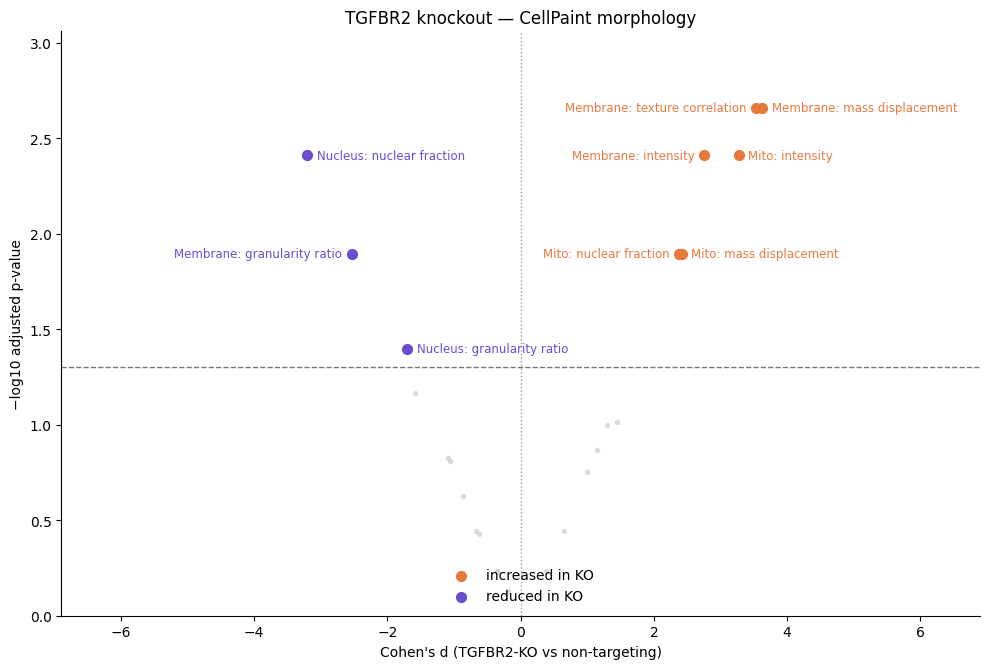

,feature,cohens_d,padj
10,Cell-Membrane::tex_corr,3.533487,0.002184
8,Cell-Membrane::mass_disp,3.628250,0.002184
0,Mitochondria::cell_mean,3.272104,0.003872
13,Nucleus::nc_ratio,-3.205087,0.003872
6,Cell-Membrane::cell_mean,2.757476,0.003872
11,Cell-Membrane::gran_ratio,-2.534610,0.012744
2,Mitochondria::mass_disp,2.414926,0.012744
1,Mitochondria::nc_ratio,2.376886,0.012744
17,Nucleus::gran_ratio,-1.700434,0.039951
15,Nucleus::radial_ratio,-1.580635,0.067897


In [9]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

morphology_targets = morphology_panel["target_name"].tolist()

# Read only the columns needed for the six measurements per morphology stain.
needed = []
for target in morphology_targets:
    candidates = [
        target,
        f"{target}_NuclearRatio",
        f"Intensity_MassDisplacement_{target}",
        f"RadialDistribution_FracAtD_4of4_{target}",
        f"RadialDistribution_FracAtD_1of4_{target}",
        *[f"Texture_Correlation_3_{direction}_256_{target}" for direction in ("00", "01", "02", "03")],
        f"Granularity_2_{target}",
        f"Granularity_6_{target}",
    ]
    missing = [name for name in candidates if name not in imaging_position]
    if missing:
        raise RuntimeError(f"Missing expected morphology features for {target}: {missing}")
    needed.extend(candidates)

morph_rows = np.flatnonzero(analysis_cells)
morph_matrix = np.asarray(
    imaging.X[morph_rows, :][:, [imaging_position[name] for name in needed]].compute(),
    dtype=float,
)
column = {name: morph_matrix[:, i] for i, name in enumerate(needed)}

morph_features = {}
for target in morphology_targets:
    intensity = np.clip(column[target], 1e-6, None)
    cofactor = max(np.nanmedian(intensity) / 5, 1e-6)
    morph_features[f"{target}::cell_mean"] = np.arcsinh(intensity / cofactor)
    morph_features[f"{target}::nc_ratio"] = column[f"{target}_NuclearRatio"]

    mass = column[f"Intensity_MassDisplacement_{target}"]
    mass_cofactor = max(np.nanmedian(np.clip(mass, 1e-6, None)) / 5, 1e-6)
    morph_features[f"{target}::mass_disp"] = np.arcsinh(mass / mass_cofactor)

    outer = column[f"RadialDistribution_FracAtD_4of4_{target}"]
    inner = column[f"RadialDistribution_FracAtD_1of4_{target}"]
    morph_features[f"{target}::radial_ratio"] = np.log2((outer + 1e-6) / (inner + 1e-6))

    texture = np.column_stack([
        column[f"Texture_Correlation_3_{direction}_256_{target}"]
        for direction in ("00", "01", "02", "03")
    ])
    morph_features[f"{target}::tex_corr"] = np.nanmean(texture, axis=1)

    granularity_2 = column[f"Granularity_2_{target}"]
    granularity_6 = column[f"Granularity_6_{target}"]
    morph_features[f"{target}::gran_ratio"] = np.log2(
        (granularity_2 + 1e-6) / (granularity_6 + 1e-6)
    )

morph_cells = pd.DataFrame(morph_features)
morph_cells["Well"] = cell_well[morph_rows]
morph_cells["guide_class"] = guide_gene[morph_rows]
morph_well_means = morph_cells.groupby(["Well", "guide_class"], observed=True).mean(numeric_only=True)

rows = []
for feature_name in morph_features:
    target_values = morph_well_means.xs(TARGET_GENE, level="guide_class")[feature_name]
    nt_values = morph_well_means.xs("NT", level="guide_class")[feature_name]
    pooled_sd = np.sqrt(
        ((len(target_values) - 1) * target_values.var(ddof=1)
         + (len(nt_values) - 1) * nt_values.var(ddof=1))
        / (len(target_values) + len(nt_values) - 2)
    )
    effect = (target_values.mean() - nt_values.mean()) / pooled_sd
    p_value = ttest_ind(target_values, nt_values, equal_var=False).pvalue
    rows.append({"feature": feature_name, "cohens_d": effect, "pvalue": p_value})

morphology_results = pd.DataFrame(rows)
morphology_results["padj"] = multipletests(morphology_results["pvalue"], method="fdr_bh")[1]
morphology_results = morphology_results.sort_values("padj")
morphology_results["minus_log10_padj"] = -np.log10(morphology_results["padj"].clip(lower=1e-300))

TARGET_LABEL = {"Cell-Membrane": "Membrane", "Mitochondria": "Mito"}
METRIC_LABEL = {
    "cell_mean": "intensity",
    "nc_ratio": "nuclear fraction",
    "mass_disp": "mass displacement",
    "radial_ratio": "radial distribution",
    "tex_corr": "texture correlation",
    "gran_ratio": "granularity ratio",
}


def morphology_label(feature_name):
    target, metric = feature_name.split("::")
    return f"{TARGET_LABEL.get(target, target)}: {METRIC_LABEL.get(metric, metric)}"


fig, ax = plt.subplots(figsize=(10, 6.8))
ax.scatter(morphology_results["cohens_d"], morphology_results["minus_log10_padj"],
           s=15, c=BACKGROUND_COLOR, alpha=0.7, linewidths=0)
significant = morphology_results["padj"] < 0.05
for rising, color, legend in ((True, UP_COLOR, "increased in KO"), (False, DOWN_COLOR, "reduced in KO")):
    side = significant & ((morphology_results["cohens_d"] > 0) == rising)
    ax.scatter(morphology_results.loc[side, "cohens_d"], morphology_results.loc[side, "minus_log10_padj"],
               s=65, c=color, linewidths=0, label=legend)

ax.axhline(-np.log10(0.05), color="#777", ls="--", lw=1)
ax.axvline(0, color="#999", ls=":", lw=1)
ax.set(xlabel="Cohen's d (TGFBR2-KO vs non-targeting)", ylabel="−log10 adjusted p-value",
       title="TGFBR2 knockout — CellPaint morphology")
widest = morphology_results["cohens_d"].abs().max()
ax.set_xlim(-widest * 1.9, widest * 1.9)
ax.set_ylim(0, morphology_results["minus_log10_padj"].max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower center")

hits = morphology_results.loc[significant]
# Labels point inward, toward the empty middle of the plot, so long names stay on the canvas.
fig.tight_layout()
label_points(ax, pd.DataFrame({
    "x": hits["cohens_d"].to_numpy(),
    "y": hits["minus_log10_padj"].to_numpy(),
    "label": [morphology_label(name) for name in hits["feature"]],
    "color": np.where(hits["cohens_d"] > 0, UP_COLOR, DOWN_COLOR),
}), outward=False, fontsize=8.5)
plt.show()

display(morphology_results.loc[:, ["feature", "cohens_d", "padj"]].head(12))

### 6.3 Protein-level state after 30 minutes of TNFα

This UMAP uses the **four biological Protein IF whole-cell intensities** discovered from panel metadata;
Mouse and Rabbit IgG controls are excluded. Intensities are arcsinh-transformed, tile-median detrended while
preserving each well's median, and standardized across the plate. Treatment is constant within each well, so
the scaling keeps each well's median; centering a well on itself would remove the treatment contrast.

For speed and a balanced view, 8,000 cells are sampled as evenly as possible across all wells. UMAP shows
how those cells arrange in protein-IF space.


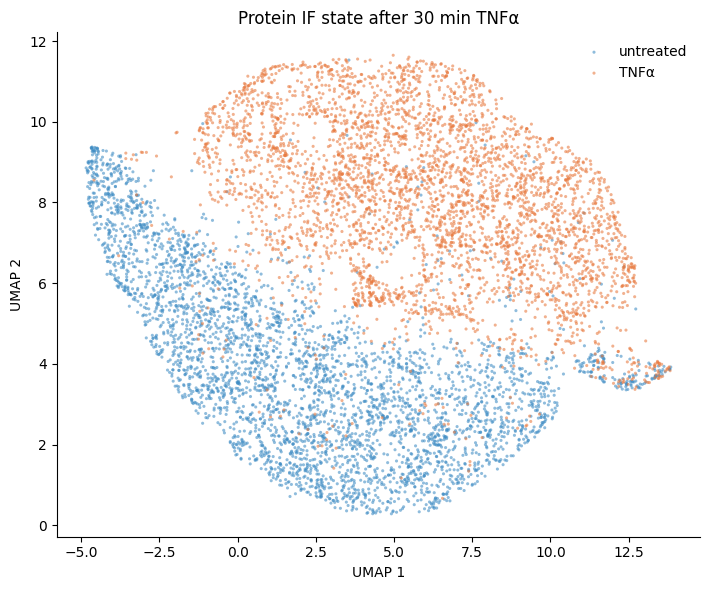

Protein markers: Phospho-ERK1_Phospho-ERK2, ERK1_ERK2, Phospho-HSP27, Phospho-p38
Cells shown: 8,000 across 12 wells


In [10]:
import contextlib
import io

# Biological Protein IF markers, excluding isotype controls by metadata role.
protein_markers = protein_panel.loc[protein_panel["role"].eq("readout"), "target_name"].tolist()
protein_columns = [imaging_position[name] for name in protein_markers]
protein_intensity = np.asarray(imaging.X[:, protein_columns].compute(), dtype=float)

protein_features = pd.DataFrame({
    "Well": cell_well,
    "WellLabel": well_label,
    "tile_id": string_values(imaging.obs["tile_id"]),
    "condition": condition,
})
for column_number, marker in enumerate(protein_markers):
    values = np.clip(protein_intensity[:, column_number], 1e-6, None)
    cofactor = max(np.nanmedian(values) / 5, 1e-6)
    protein_features[marker] = np.arcsinh(values / cofactor)

    # Remove tile offsets but add the well median back, preserving between-well biology.
    well_median = protein_features.groupby("Well")[marker].transform("median")
    tile_median = protein_features.groupby(["Well", "tile_id"])[marker].transform("median")
    protein_features[marker] = protein_features[marker] - tile_median + well_median

# Exact, balanced allocation of at most 8,000 cells over all wells.
rng = np.random.default_rng(42)
MAX_UMAP_CELLS = 8_000
well_groups = list(protein_features.groupby("Well", sort=True).groups.items())
base, remainder = divmod(min(MAX_UMAP_CELLS, len(protein_features)), len(well_groups))
sampled = []
for number, (_, indices) in enumerate(well_groups):
    n_take = min(len(indices), base + (number < remainder))
    sampled.append(rng.choice(np.asarray(indices), size=n_take, replace=False))
sampled = np.concatenate(sampled)
rng.shuffle(sampled)

protein_matrix = protein_features.loc[sampled, protein_markers].to_numpy(dtype=float)
protein_matrix = np.nan_to_num(protein_matrix)
scale = protein_matrix.std(axis=0)
scale[scale < 1e-8] = 1
protein_matrix = (protein_matrix - protein_matrix.mean(axis=0)) / scale

# umap-learn imports optional TensorFlow modules noisily on some installations; suppress that import chatter.
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import umap
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="n_jobs value 1 overridden")
    protein_umap = umap.UMAP(
        n_neighbors=30, min_dist=0.3, n_epochs=500, random_state=42
    ).fit_transform(protein_matrix)

sample_condition = protein_features.loc[sampled, "condition"].to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 6))
condition_order = [name for name in ("untreated", "TNFα") if name in set(sample_condition)]
palette = {"untreated": "#3E8CC4", "TNFα": "#E8793E"}
for group in condition_order:
    mask = sample_condition == group
    ax.scatter(protein_umap[mask, 0], protein_umap[mask, 1], s=5, alpha=0.58,
               color=palette[group], label=group, edgecolors="none")
ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title="Protein IF state after 30 min TNFα")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print("Protein markers:", ", ".join(protein_markers))
print(f"Cells shown: {len(sampled):,} across {len(well_groups)} wells")


## Next steps

- Try the same comparisons with a different confidence threshold or gene target.
- See [`GettingStarted.ipynb`](../GettingStarted.ipynb) for the basics of loading tables.
- Field-level reference: [`spatialdata_object_overview.md`](../../docs/spatialdata_object_overview.md),
  [`anndata_object_overview.md`](../../docs/anndata_object_overview.md).
